# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Adem BEN NJIMA   Student ID: B00818393
2. Full name: Kenza GUEDDAS    Student ID: B00822443
3. Full name: Jawad MALLAT     Student ID: B00820811
4. Full name: Erdem SANVER     Student ID: B00818169
5. Full name: Deha TANACI      Student ID: _______________

**Group / repo name:** `aidams-lab5-bennjima-gueddas-mallat-sanver-tanaci`
**Submitter (one person):** Jawad MALLAT

**Project role (consultant / data scientist / risk analyst):** Sustainability consultant (Oil & Gas sector, natural gas / LNG imports to the EU)
**Key quantity (one sentence, with unit):** Upstream methane embedded in EU27 natural-gas imports from our six scope suppliers (Qatar, Russia, United States, Norway, Algeria, Nigeria), i.e. Eurostat import volumes x each supplier's Climate TRACE methane intensity of oil & gas production, in **kt CH4 per year**.
**Repo URL:** https://github.com/Jawadmallat/aidams-lab5-bennjima-gueddas-mallat-sanver-tanaci

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False  # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # Project data (built by fetch_data.py): Climate TRACE CH4, Eurostat EU27 imports, OWID / Energy Institute production
    TWH_PER_BCM = 10.0          # 1 bcm natural gas = 36 PJ (Energy Institute convention)
    BOE_PER_TWH = 1e9 / 1700    # 1 boe = 1.7 MWh (6.12 GJ)
    DATA = Path("data")
    sup = pd.read_csv(DATA / "suppliers.csv")
    ch4 = pd.read_csv(DATA / "climate_trace_emissions.csv").query("subsector == 'oil-and-gas-production'")
    prod = pd.read_csv(DATA / "hydrocarbon_production.csv")
    imports = pd.read_csv(DATA / "eu_gas_imports.csv").merge(sup, on="iso2")

    # intensity = CH4 of oil & gas production / oil + gas output (energy allocation); embedded = EU imports x intensity
    panel = (imports.merge(prod, on=["iso3", "year"]).merge(ch4[["iso3", "year", "ch4_t"]], on=["iso3", "year"])
             .assign(imports_bcm=lambda d: d.imports_mio_m3 / 1e3,
                     intensity_kg_boe=lambda d: d.ch4_t * 1e3 / ((d.gas_twh + d.oil_twh) * BOE_PER_TWH),
                     embedded_kt=lambda d: d.imports_bcm * TWH_PER_BCM * BOE_PER_TWH * d.intensity_kg_boe / 1e6))
    assert panel.groupby("year").size().eq(len(sup)).all()
    series = panel.groupby("year", as_index=False).embedded_kt.sum().rename(columns={"embedded_kt": "value"})
    NAME, UNIT = "Upstream methane embedded in EU gas imports (6 suppliers)", "kt CH4"

    print("Methane intensity of oil & gas production (kg CH4 / boe)")
    display(panel.pivot(index="country", columns="year", values="intensity_kg_boe"))
    print("2024 by supplier")
    display(panel.query("year == 2024").set_index("country")[["imports_bcm", "intensity_kg_boe", "embedded_kt"]]
            .assign(share_of_embedded=lambda d: d.embedded_kt / d.embedded_kt.sum()).sort_values("embedded_kt", ascending=False))
series

Methane intensity of oil & gas production (kg CH4 / boe)


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
country,,,,,,,,,,
Algeria,6.05,5.38,5.13,4.90,4.98,5.07,4.50,4.77,4.90,4.44
Nigeria,1.85,2.08,2.05,2.03,1.96,2.00,2.09,2.27,2.26,2.23
Norway,0.24,0.23,0.23,0.24,0.23,0.22,0.21,0.21,0.20,0.23
Qatar,0.84,0.84,0.86,0.84,0.85,0.87,0.87,0.89,0.87,0.86
Russia,1.53,1.51,1.48,1.47,1.49,1.58,1.50,1.57,1.61,1.27
United States,1.29,1.29,1.24,1.15,1.08,1.06,1.03,0.99,0.99,1.08


2024 by supplier


,imports_bcm,intensity_kg_boe,embedded_kt,share_of_embedded
country,,,,
Algeria,40.13,4.44,"1,047.05",0.56
United States,46.29,1.08,293.77,0.16
Russia,37.84,1.27,282.02,0.15
Norway,84.68,0.23,114.10,0.06
Nigeria,5.87,2.23,76.84,0.04
Qatar,11.06,0.86,56.22,0.03


,year,value
0,2015,"2,564.47"
1,2016,"3,035.67"
2,2017,"2,986.29"
3,2018,"2,763.83"
4,2019,"2,707.42"
5,2020,"2,647.78"
6,2021,"2,894.56"
7,2022,"2,550.57"
8,2023,"2,119.85"
9,2024,"1,870.00"


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

- **What it measures:** the upstream methane linked to the EU27's gas imports from our six suppliers, in **kt CH4 per year**: Eurostat import volume x each supplier's Climate TRACE methane intensity of oil & gas production. It was **1,870 kt in 2024**, and **Algeria alone is 56%** of it (intensity **4.44 kg CH4/boe**, against **0.23** for Norway).
- **Decision:** which suppliers EU buyers and regulators should use to replace Russian and Hormuz-blocked Qatari volumes, and whether to tie new contracts to measured methane intensity under the EU Methane Regulation (2024/1787).
- **Sources of uncertainty:**
  - **A**: year-to-year swings in import volumes (weather, prices, demand).
  - **E**: Climate TRACE intensities are modelled country averages. Methane is split between oil and gas by energy content, and an exported cargo can come from a cleaner or dirtier field than the national average.
  - **S**: how long the Hormuz disruption lasts, the Russian phase-out, and which supplier fills the gap.

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model="linear", level=0.90):
    y = train["value"].to_numpy(float)
    if model == "loglinear":
        assert (y > 0).all(), "loglinear needs positive values"
        y = np.log(y)
    years = train["year"].to_numpy()
    t0 = years.mean()                                   # centre the year
    X = np.column_stack([np.ones(len(y)), years - t0])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    n, p = X.shape
    s = np.sqrt(((y - X @ beta) ** 2).sum() / (n - p))

    new_years = np.arange(years.max() + 1, years.max() + 1 + horizon)
    X0 = np.column_stack([np.ones(horizon), new_years - t0])
    lev = np.einsum("ij,jk,ik->i", X0, np.linalg.inv(X.T @ X), X0)    # x0' (X'X)^-1 x0
    half = stats.t.ppf(0.5 + level / 2, n - p) * s * np.sqrt(1 + lev)
    mean = X0 @ beta
    out = pd.DataFrame({"year": new_years, "mean": mean, "lo": mean - half, "hi": mean + half})
    if model == "loglinear":                            # back to the original scale (mean = median here)
        out[["mean", "lo", "hi"]] = np.exp(out[["mean", "lo", "hi"]])
    return out


H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = (pd.concat([fit_predict(train, H, m).assign(model=m) for m in ["linear", "loglinear"]])
            .merge(test.rename(columns={"value": "actual"}), on="year"))
backtest["inside"] = backtest["actual"].between(backtest["lo"], backtest["hi"])
display(backtest)

,year,mean,lo,hi,model,actual,inside
0,2020,"2,815.75","2,040.79","3,590.72",linear,"2,647.78",True
1,2021,"2,817.16","1,922.31","3,712.01",linear,"2,894.56",True
2,2022,"2,818.57","1,789.91","3,847.23",linear,"2,550.57",True
3,2023,"2,819.97","1,648.34","3,991.61",linear,"2,119.85",True
4,2024,"2,821.38","1,500.58","4,142.18",linear,"1,870.00",True
5,2020,"2,818.40","2,138.54","3,714.38",loglinear,"2,647.78",True
6,2021,"2,822.54","2,052.15","3,882.13",loglinear,"2,894.56",True
7,2022,"2,826.68","1,959.50","4,077.63",loglinear,"2,550.57",True
8,2023,"2,830.83","1,864.95","4,296.97",loglinear,"2,119.85",True
9,2024,"2,834.99","1,771.04","4,538.11",loglinear,"1,870.00",True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

,inside,n
model,,
linear,5,5
loglinear,5,5


,"P(X >= k), X ~ Bin(5, 0.1)"
misses k,
0,1.00
1,0.41
2,0.08
3,0.01
4,0.00
5,0.00


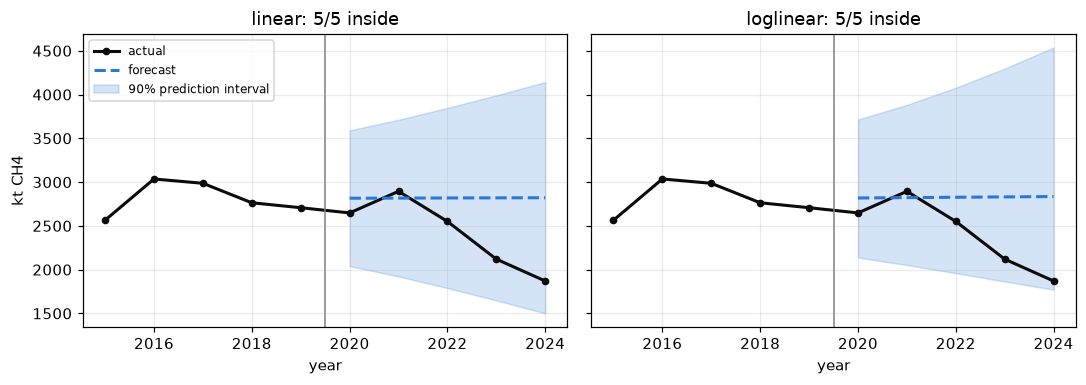

In [4]:
display(backtest.groupby("model")["inside"].agg(inside="sum", n="size"))

k = np.arange(6)
display(pd.DataFrame({"misses k": k, "P(X >= k), X ~ Bin(5, 0.1)": stats.binom.sf(k - 1, 5, 0.1)}).set_index("misses k"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, m in zip(axes, ["linear", "loglinear"]):
    b = backtest[backtest.model == m]
    ax.plot(series.year, series.value, "o-", color="#0b0b0b", lw=2, ms=4, label="actual")
    ax.plot(b.year, b["mean"], "--", color="#2a78d6", lw=2, label="forecast")
    ax.fill_between(b.year, b.lo, b.hi, color="#2a78d6", alpha=0.2, label="90% prediction interval")
    ax.axvline(train.year.max() + 0.5, color="grey", lw=1)
    ax.set_title(f"{m}: {b.inside.sum()}/{len(b)} inside"); ax.set_xlabel("year")
axes[0].set_ylabel(UNIT); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Your answer (Q2):**

- **(a)** Hold-out 2020-2024, trained on 2015-2019: **linear 5/5** and **loglinear 5/5** years inside the 90% band. That is only because the bands are very wide with 5 training points (linear 2024: **1,501 to 4,142 kt**). Both point forecasts stay flat at about **2,820 kt** and miss the post-2022 fall (actual 2024: **1,870 kt**). The optional rolling back-test gives coverage of only **50-80%** at horizons of 1-3 years.
- **(b)** With X ~ Bin(5, 0.1): P(X >= 1) = **0.41**, P(X >= 2) = **0.08**, P(X >= 3) = **0.01**. So **2 misses** would already make us doubt the band (p < 0.10), and 3 would reject it. We had 0 misses, so the band is not rejected, but 5 points is a weak test.
- **(c)** We keep **linear** as the benchmark (narrower and symmetric). The gap between the two models is tiny, so the functional form is not the problem. The problem is the **structural break** (Russian supply cut in 2022), which no trend fitted on 2015-2019 can see. For 2030 we therefore use **no trend** and simulate from the 2024 level instead.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# Our series has only 10 years, so the "10th year" rule would leave no test point:
# we start with a 5-year training window instead (cutoffs 2019-2023).
rows = []
for c in range(5, len(series)):
    tr = series.iloc[:c]
    for m in ["linear", "loglinear"]:
        pr = fit_predict(tr, 3, m).merge(series, on="year")
        rows.append(pr.assign(model=m, h=pr.year - tr.year.max(), inside=pr.value.between(pr.lo, pr.hi)))
rolling = pd.concat(rows)
display(rolling.groupby(["model", "h"])["inside"].agg(coverage="mean", n="size").unstack("model"))

coverage                n          
model   linear loglinear linear loglinear
h                                        
1         0.80      0.60      5         5
2         0.50      0.50      4         4
3         0.67      0.67      3         3

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET = 2030      # EU Methane Regulation (2024/1787) import requirements apply from 2030

# Fixed parts: supplier intensities (mean of 2022-2024 to smooth year-to-year noise) and the 2024 supply mix
I = panel.query("year >= 2022").groupby("country")["intensity_kg_boe"].mean()
vol = panel.groupby("year")["imports_bcm"].sum()
mix_2024 = panel.query("year == 2024").set_index("country")["imports_bcm"]
BASE_MIX = mix_2024 / mix_2024.sum()


def compute_quantity(volume_bcm, intensity_mult, mix=BASE_MIX):
    """Embedded methane (kt CH4) = import volume x boe per bcm x mix-weighted intensity x intensity multiplier."""
    mix_intensity = (mix.reindex(I.index, fill_value=0) * I).sum()             # kg CH4 / boe
    return volume_bcm * TWH_PER_BCM * BOE_PER_TWH * mix_intensity * intensity_mult / 1e6


# Input 1, import volume in 2030 (bcm): centred on 2024 (no trend, see Part B), random walk with the observed
#   sd of annual changes over 6 years.
V0, V_SD = vol[2024], vol.diff().std() * np.sqrt(TARGET - 2024)
# Input 2, multiplier on Climate TRACE intensities: Triangular(0.7, 1.0, 1.6). Mode 1 = we trust the dataset;
#   right-skewed because measurement campaigns tend to find more methane than inventories (our assumption).
MULT = (0.7, 1.0, 1.6)

rng = np.random.default_rng(SEED)
vol_draws = rng.normal(V0, V_SD, N)
mult_draws = rng.triangular(*MULT, N)
q_base = compute_quantity(vol_draws, mult_draws)


def interval(a):
    lo, med, hi = np.percentile(a, [5, 50, 95])
    return pd.Series({"p5": lo, "median": med, "p95": hi, "rel_half_width": (hi - lo) / (2 * med)})


print(f"Input 1 volume ~ Normal({V0:.1f}, {V_SD:.1f}) bcm | sd of annual change {vol.diff().std():.1f} bcm")
print(f"2024 mix intensity: {(BASE_MIX * I).sum():.2f} kg CH4/boe")
sens = pd.DataFrame({
    "both vary": interval(q_base),
    "volume fixed at median": interval(compute_quantity(np.median(vol_draws), mult_draws)),
    "intensity fixed at median": interval(compute_quantity(vol_draws, np.median(mult_draws))),
}).T
display(sens)

Input 1 volume ~ Normal(225.9, 55.4) bcm | sd of annual change 22.6 bcm
2024 mix intensity: 1.47 kg CH4/boe


,p5,median,p95,rel_half_width
both vary,"1,171.17","2,081.01","3,343.19",0.52
volume fixed at median,"1,589.03","2,119.67","2,816.32",0.29
intensity fixed at median,"1,244.74","2,119.67","2,962.39",0.41


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

- **(a)** 2030, 2024 supply mix: median **2,081 kt CH4**, 90% interval **[1,171, 3,343] kt** (relative half-width **52%**).
- **(b)** Fixing the **import volume** shrinks the half-width most: from **52% to 29%**. Fixing the intensity multiplier only gets it to **41%**. Volume, as we modelled it here, is mainly **aleatoric**: random year-to-year swings in demand, weather and prices (sd of annual change **22.6 bcm**).
- **(c)** With one more week, we would collect **measured intensities** (satellite super-emitter detections, MiQ-certified volumes, operator MRV reports, especially for Algeria) to narrow the epistemic multiplier, plus **contracted LNG / pipeline volumes to 2030** to remove the predictable part of volume uncertainty. The year-to-year swing in how much gas Europe actually burns (weather, prices) would remain whatever we do.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [7]:
# Scenarios = changes to the supply mix (Part C inputs unchanged). In S1-S3 the volumes lost from Russia
# (sanctions / EU phase-out) and Qatar (Hormuz) are replaced by one alternative supplier.
lost = BASE_MIX[["Russia", "Qatar"]].sum()

def replace_with(country):
    mix = BASE_MIX.drop(["Russia", "Qatar"])
    mix[country] += lost
    return mix

scenarios = {
    "S0 status quo (2024 mix)": BASE_MIX,
    "S1 RU+QA -> US LNG": replace_with("United States"),
    "S2 RU+QA -> Algeria": replace_with("Algeria"),
    "S3 RU+QA -> Norway": replace_with("Norway"),
}
draws = {name: compute_quantity(vol_draws, mult_draws, mix) for name, mix in scenarios.items()}

scen = pd.DataFrame({name: interval(d) for name, d in draws.items()}).T
scen["width_90"] = scen["p95"] - scen["p5"]
scen[f"P(> {series.year.iloc[-1]} level)"] = [(d > series.value.iloc[-1]).mean() for d in draws.values()]
scen.insert(0, "mix_kg_per_boe", [(m.reindex(I.index, fill_value=0) * I).sum() for m in scenarios.values()])
display(scen)

gap = scen["median"].max() - scen["median"].min()
print(f"Russia + Qatar share of 2024 volume: {lost:.1%}")
print(f"largest gap between scenario medians: {gap:,.0f} {UNIT} "
      f"({scen['median'].idxmax()} vs {scen['median'].idxmin()})")
print(f"90% width within a scenario: {scen['width_90'].min():,.0f} to {scen['width_90'].max():,.0f} {UNIT}")
# Scenarios share the same input draws, so their difference is much tighter than either band
diff = draws["S2 RU+QA -> Algeria"] - draws["S3 RU+QA -> Norway"]
print(f"paired difference S2 - S3: median {np.median(diff):,.0f}, 90% [{np.percentile(diff, 5):,.0f}, "
      f"{np.percentile(diff, 95):,.0f}] {UNIT}; P(S2 > S3) = {(diff > 0).mean():.0%}")


,mix_kg_per_boe,p5,median,p95,rel_half_width,width_90,P(> 2024 level)
S0 status quo (2024 mix),1.47,"1,171.17","2,081.01","3,343.19",0.52,"2,172.02",0.64
S1 RU+QA -> US LNG,1.40,"1,115.45","1,982.02","3,184.15",0.52,"2,068.69",0.57
S2 RU+QA -> Algeria,2.20,"1,748.99","3,107.72","4,992.62",0.52,"3,243.63",0.93
S3 RU+QA -> Norway,1.23,976.72,"1,735.51","2,788.13",0.52,"1,811.40",0.40


Russia + Qatar share of 2024 volume: 21.6%
largest gap between scenario medians: 1,372 kt CH4 (S2 RU+QA -> Algeria vs S3 RU+QA -> Norway)
90% width within a scenario: 1,811 to 3,244 kt CH4
paired difference S2 - S3: median 1,372, 90% [772, 2,204] kt CH4; P(S2 > S3) = 100%


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

- **Largest gap between scenario medians:** **1,372 kt CH4** (S2 Algeria replaces RU+QA: **3,108** vs S3 Norway: **1,736**). S1 US LNG (**1,982**) is close to the status quo (**2,081**).
- **Width within one scenario:** the 90% width is **1,811 to 3,244 kt** (status quo **2,172**), so **the width is bigger than the scenario gap**.
- **But** the scenarios share the same volume and intensity draws, so the **paired** difference S2 - S3 is **[772, 2,204] kt** and is positive in **100%** of draws. The ranking of suppliers is robust even though the bands overlap.
- **Presentation:** **one band per scenario**, not one merged fan. The scenario is a sourcing choice, not a probability. We also report the paired gap next to the figure, so overlapping bands are not read as "the choice does not matter".

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [8]:
# Skipped: Part E needs paid LLM API calls / keys plus a hand-labelled gold sample of supplier documents.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

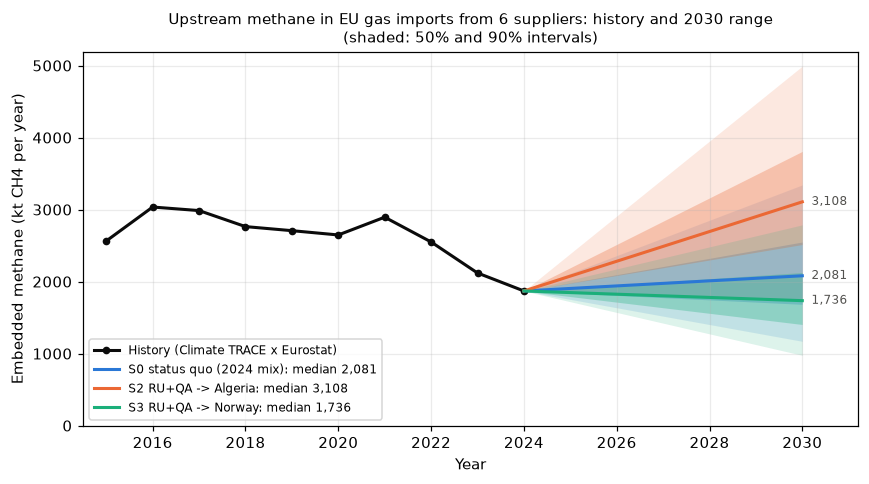

In [9]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]          # fixed categorical order, 3 series max
SHOW = ["S0 status quo (2024 mix)", "S2 RU+QA -> Algeria", "S3 RU+QA -> Norway"]
last_year, last_value = series.year.iloc[-1], series.value.iloc[-1]
fut = np.arange(last_year, TARGET + 1)
w = (fut - last_year) / (TARGET - last_year)         # widen the bands linearly from today's value to 2030

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(series.year, series.value, "o-", color="#0b0b0b", lw=2, ms=4, label="History (Climate TRACE x Eurostat)")
for name, col in zip(SHOW, COLORS):
    q5, q25, q50, q75, q95 = np.percentile(draws[name], [5, 25, 50, 75, 95])
    path = lambda q: last_value + w * (q - last_value)
    ax.fill_between(fut, path(q5), path(q95), color=col, alpha=0.15, lw=0)
    ax.fill_between(fut, path(q25), path(q75), color=col, alpha=0.30, lw=0)
    ax.plot(fut, path(q50), color=col, lw=2, label=f"{name}: median {q50:,.0f}")
    ax.annotate(f"{q50:,.0f}", (TARGET, q50), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Year")
ax.set_ylabel(f"Embedded methane ({UNIT} per year)")
ax.set_title("Upstream methane in EU gas imports from 6 suppliers: history and 2030 range\n(shaded: 50% and 90% intervals)", fontsize=10)
ax.set_xlim(series.year.min() - 0.5, TARGET + 1.2)
ax.set_ylim(0, None)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
fig.savefig("fig_uncertainty.png", dpi=300, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

> **Uncertainty and limitations.** We project the upstream methane embedded in EU gas imports from six suppliers to 2030. With the 2024 supply mix, the median is 2,081 kt CH4 (90% interval: 1,171-3,343 kt). A hold-out back-test kept all five years (2020-2024) inside the 90% band, but only because the band was wide. The trend missed the post-2022 fall, so we project without one. Import volume drives the range: fixing it cuts the relative half-width from 52% to 29%. Supplier choice matters as much. Replacing Russian and Qatari gas with Algerian rather than Norwegian gas adds a median 1,372 kt. In that Algerian case, a rise above the 2024 level is very likely (93%). Limitation: intensities are modelled country averages, split between oil and gas by energy content, not measured per cargo.

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is* **how replacement gas is contracted**: the total stays uncertain, but Algerian gas beats Norwegian gas on methane in 100% of our draws, so EU buyers should fill the Russian/Qatari gap with Norwegian and US volumes first and make any new Algerian contracts conditional on measured, certified methane intensity under EU 2024/1787.*"